# TP6 – RAG Agentique (LangChain + LangGraph)

In [29]:
# Installation (à exécuter une seule fois)
# !pip install -q langchain langchain-core langchain-community langchain-openai langchain-text-splitters langgraph chromadb pypdf tiktoken ipython

In [30]:
import os
from dotenv import load_dotenv

load_dotenv(override=True)

GOOGLE_API_KEY = os.getenv("GOOGLE_API_KEY")
print("Google:", "OK" if GOOGLE_API_KEY else "Missing")

Google: OK


In [31]:
import sys, subprocess
subprocess.check_call([sys.executable, "-m", "ensurepip", "--upgrade"])
subprocess.check_call([sys.executable, "-m", "pip", "install", "python-dotenv", "langchain-groq", "langchain-tavily", "langgraph"])

0

In [32]:
import sys, subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "install",
    "langchain", "langchain-core", "langchain-community",
    "langchain-text-splitters", "langchain-google-genai",
    "langgraph", "chromadb", "pypdf", "tiktoken",
    "python-dotenv", "ipython"
])

0

In [33]:
import os
import logging
from typing import Annotated, Sequence, Literal
from typing_extensions import TypedDict

from IPython.display import Markdown, Image, display

from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain_community.vectorstores import Chroma
from langchain_google_genai import ChatGoogleGenerativeAI , GoogleGenerativeAIEmbeddings
from langchain_core.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode


## Étape 1 : Chargement des documents PDF

In [34]:
# Chemin de tous les documents : AI Initiatives
ai_initiative_pdf_paths = [f"./resources/{file}" for file in os.listdir("./resources")]
print(ai_initiative_pdf_paths)

['./resources/Ibtissam AIT BOUZIAN.pdf']


In [35]:
# Création de l'objet loader PDF
loader = PyPDFDirectoryLoader(path="./resources/")

## Étape 2 : Découpage en chunks

In [36]:
# Découpage des documents en chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    encoding_name="cl100k_base",
    chunk_size=1000,
    chunk_overlap=200
)

# Chargement et découpage
ai_initiative_chunks = loader.load_and_split(text_splitter=text_splitter)
print(f"Nombre de chunks : {len(ai_initiative_chunks)}")

Nombre de chunks : 1


## Étape 4 : Création du Vector Store avec les embeddings

In [37]:
# Initialisation du modèle d'embedding OpenAI
embedding_model = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

# Création du vector store à partir des documents
vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)

# Retriever pour la recherche par similarité
# qui récupère les 10 chunks les plus pertinents
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 10}
)

16:05:55 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"


## Étape 5 : Test manuel du retrieval

In [38]:
# Requête de test
test_query = "What AI projects is Microsoft working on?"
print(f"🔍 Test Query: {test_query}")
print("=" * 80)

# Récupération des documents pertinents
relevant_docs = retriever.invoke(test_query)
print(f"\n Retrieved {len(relevant_docs)} relevant chunks:\n")

# Affichage du top 3
for i, doc in enumerate(relevant_docs[:3], 1):
    print(f"📄 Result {i}:")
    print(f"   Source: {doc.metadata.get('source', 'Unknown')}")
    print(f"   Page: {doc.metadata.get('page', 'Unknown')}")
    print(f"   Content: {doc.page_content[:100]}...")
    print("-" * 80 + "\n")

🔍 Test Query: What AI projects is Microsoft working on?


16:05:55 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"



 Retrieved 2 relevant chunks:

📄 Result 1:
   Source: resources\Ibtissam AIT BOUZIAN.pdf
   Page: 0
   Content: IBTISSAM AIT BOUZIAN
Étudiante en Master Intelligence Artificielle & Digital Computing (AIDC)
Recher...
--------------------------------------------------------------------------------

📄 Result 2:
   Source: resources\Ibtissam AIT BOUZIAN.pdf
   Page: 0
   Content: IBTISSAM AIT BOUZIAN
Étudiante en Master Intelligence Artificielle & Digital Computing (AIDC)
Recher...
--------------------------------------------------------------------------------



## Étape 6 : Outil retriever

In [39]:
@tool
def retriever_tool(query: str) -> str:
    """Interrogez la base de données privée des rapports d'analystes et des documents sur les initiatives en IA.

    Cet outil alimenté par RAG effectue des recherches dans des documents internes de l'entreprise concernant
    les initiatives en IA, les projets de recherche, les domaines d'innovation et les investissements
    technologiques stratégiques.

    Utilisez cet outil lorsque vous avez besoin d'informations sur :
    - Les projets de recherche et les initiatives en IA de l'entreprise
    - Les domaines d'innovation en IA et les axes prioritaires
    - Les feuilles de route technologiques et les plans futurs
    - Les calendriers et les détails de projets d'IA spécifiques

    Args:
        query: Requête en langage naturel sur les initiatives en IA de l'entreprise
               (p. ex., « Sur quels projets d'IA Microsoft travaille-t-elle ? »,
               « Les domaines de recherche en IA de NVIDIA »,
               « La chronologie de l'IA chez Amazon »)

    Returns:
        str: Contexte issu des rapports privés d'analystes
    """
    try:
        # Récupération des chunks pertinents
        relevant_document_chunks = retriever.invoke(query)
        context_list = [d.page_content for d in relevant_document_chunks]
        context_for_query = ". ".join(context_list)
        return context_for_query
    except Exception as e:
        return f"Error querying private database: {str(e)}"

In [40]:
# Initialisation du modèle d'embedding Gemini
embedding_model = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

# Création du vector store à partir des documents
vectorstore = Chroma.from_documents(
    documents=ai_initiative_chunks,
    embedding=embedding_model,
    collection_name="AI_Initiatives"
)

# Retriever : récupère les 4 chunks les plus pertinents
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

16:05:56 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"


## State et System message

In [41]:
# Logging pour suivre le processus de décision de l'agent
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s',
    datefmt='%H:%M:%S'
)
logger = logging.getLogger(__name__)

In [42]:
class SimpleAgentState(TypedDict):
    """
    État de l'agent de recherche financière.
    Conserve l'historique de la conversation avec accumulation des messages.
    """
    messages: Annotated[Sequence, add_messages]

In [43]:
agentic_rag_system_message = """
Vous êtes un assistant spécialisé dans l'examen des
initiatives en IA des entreprises et dans la fourniture
de réponses exactes fondées sur le contexte fourni.
Les données fournies par l'utilisateur incluront tout le
contexte nécessaire pour répondre à sa question.
Le contexte contient des références à des initiatives,
projets ou programmes d'IA spécifiques d'entreprises,
pertinents pour la requête de l'utilisateur.
Répondez uniquement en utilisant le contexte fourni.
N'ajoutez pas d'informations externes et ne mentionnez
pas le contexte dans votre réponse.
Citez toujours de quelle entreprise provient
l'information.
Si la réponse ne peut pas être trouvée dans le contexte,
répondez par : "Je ne sais pas - cette information n'est
pas disponible dans nos rapports d'analystes."
"""

## Agent Node

In [44]:
def agent_node(state: SimpleAgentState) -> dict:
    """Noeud agent : appelle le LLM avec le prompt système et l'état courant."""
    logger.info("AGENT NODE: Processing request...")

    # Préparation des messages avec le prompt système
    system_msg = SystemMessage(content=agentic_rag_system_message)
    messages = [system_msg] + list(state["messages"])

    # Appel du modèle
    logger.info("Calling LLM with tools...")
    response = llm_with_tools.invoke(messages)

    # Log si l'agent veut utiliser des outils
    if hasattr(response, "tool_calls") and response.tool_calls:
        logger.info(f"✓ Agent decided to use {len(response.tool_calls)} tool(s)")
        for i, tool_call in enumerate(response.tool_calls, 1):
            logger.info(f"   {i}. {tool_call['name']}")
    else:
        logger.info("   ✓ Agent generated final response (no tools needed)")

    return {"messages": [response]}

## Condition de routage

In [45]:
model = ChatGoogleGenerativeAI(
    model="gemini-3.5-flash",   # si refusé : "gemini-flash-latest"
    temperature=0,
    max_retries=3,
    timeout=120,
)
tools = [retriever_tool]
llm_with_tools = model.bind_tools(tools)

In [46]:
print(model.invoke("Dis bonjour en une phrase.").content)

16:05:57 [INFO] AFC is enabled with max remote calls: 10.
16:06:02 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"


[{'type': 'text', 'text': 'Bonjour, je vous souhaite une excellente journée !', 'extras': {'signature': 'EoAICv0HAWkUfRPsKU2v6CZ++3vz1ZpjCad8cPRcot0tvN9sOyHqpz1GBOu/RmN1OCILYrA/TOf7x2pV0Q1u3wDrOo+k39MF9PwIsvHn6N5AlBIAzrFRRZ6jVvhYs8R4PVbqRjx/IeS7CjAC5EiIy1tbiwSg1NyDMryjHpO/lLAZTYy8wahFljZrtzRc3mhRJCTv84cGzY77idrOtzTlW8Vy/v7E5i/Hsw0CiZWJ9kGcWA9AfL/hmfoyjobC0kJi9y1iXkJWCLHmouQ29WYHdqqUnMhTeqxJ/G13vGJlgFtoop79a/+A+akc4roLOVjySn0Ts2cVXkkrMHhwtTy4+GpvN0y72EkhO22RUqOXWtp0TAXpzPOUl8P3sPtbpOq2dOoU1WaDWdqdMYGNvChjF/CKGHgM3FM/VujM6p32OHfdmX8KD/mYzr6gdFAtXMt1GA13+fxGRqTmsoP6eJ6ho3xZzYpykhCBUEJfVaXS//+JvI4cpfDudjzX8UAIJv3WhEX+Vv+kB9JTM92D1byb9Y7p+s8VbDSFUSwzL9xx3Jsai0/hysvDSpoFso6bw2r5KAnP9rufFP3qUH3CXHoGIudnxEBQfW7CcSSC5nKzle+/KUSEnuLL4Cu/Azl2N/p33x38rWSnN89h6xX/dN7J0vlGCd1hgbWkhaSJF7K+hw5pW11Wuv69y8AExm8pO/qgePCPU+mcz4gZEGD6a8594jOju+ZZY+8pB8VQfq4YHQoVcOlYcSl5Xm0TkMVTXQr1xx4AQCsLEUAiglNXRp1F2sF2OAdNdYbgHQHRTkpIBwE2s6NW1VFXREKBI+1x0OWa21pW3/8OvmJbQfoOxQGM9hXsIKr9w972I4rMpLWelSRQtsep8HFrVTbdzZ4yeCz

In [47]:
from google import genai
client = genai.Client(api_key=GOOGLE_API_KEY)
for m in client.models.list():
    if "flash" in m.name:
        print(m.name)

16:06:04 [INFO] HTTP Request: GET https://generativelanguage.googleapis.com/v1beta/models "HTTP/1.1 200 OK"
16:06:04 [INFO] HTTP Request: GET https://generativelanguage.googleapis.com/v1beta/models?pageToken=Chltb2RlbHMvZ2VtaW5pLWVtYmVkZGluZy0y "HTTP/1.1 200 OK"


models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


## Création, compilation et affichage du graphe

In [48]:
# Création du workflow
workflow = StateGraph(SimpleAgentState)

# Noeud d'outils avec logging
original_tool_node = ToolNode(tools)

def tool_node_with_logging(state):
    logger.info("TOOL NODE: Executing tools...")
    result = original_tool_node.invoke(state)
    logger.info("Tools executed successfully")
    return result

# Ajout des noeuds
workflow.add_node("agent", agent_node)
workflow.add_node("tools", tool_node_with_logging)

# Point d'entrée
workflow.set_entry_point("agent")

16:06:04 [INFO] ✅ Enhanced agent created successfully



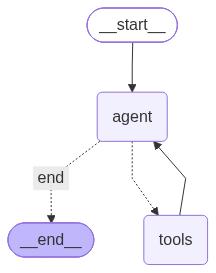

In [49]:
# Arête conditionnelle depuis l'agent
workflow.add_conditional_edges(
    "agent",
    should_continue,
    {
        "tools": "tools",
        "end": END
    }
)

# Arête des outils vers l'agent
workflow.add_edge("tools", "agent")

graph = workflow.compile()
logger.info("✅ Enhanced agent created successfully\n")

display(Image(graph.get_graph().draw_mermaid_png()))

## Tester l'application Agentic RAG

In [50]:
retriever = vectorstore.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 4}
)

In [51]:
import time

print("=" * 80)
print("TEST 5: Enhanced Agent with RAG - AI Research Activity Check")
print("=" * 80 + "\n")

query = (
    "Provide a comprehensive investment analysis for NVIDIA (NVDA) "
    "and Google including their AI research initiatives"
)
print(f"Query: {query}\n")
print("-" * 80 + "\n")

result = None
for attempt in range(1, 4):
    try:
        result = graph.invoke({"messages": [HumanMessage(content=query)]})
        break
    except Exception as e:
        msg = str(e)
        if "503" in msg or "429" in msg:
            print(f"⚠️ Erreur temporaire, tentative {attempt}/3...")
            time.sleep(10 * attempt)
        else:
            raise   # 404, clé invalide, etc. : inutile de réessayer

if result is None:
    raise RuntimeError("Gemini reste indisponible, réessayez dans quelques minutes.")

# Gemini peut renvoyer le contenu sous forme de liste de blocs
content = result["messages"][-1].content
if isinstance(content, list):
    content = "".join(
        b.get("text", "") if isinstance(b, dict) else str(b) for b in content
    )

print("\n🤖 ENHANCED AGENT RESPONSE (with RAG):")
print("=" * 80)
display(Markdown(content))
print("\n" + "=" * 80)

16:06:06 [INFO] AGENT NODE: Processing request...
16:06:06 [INFO] Calling LLM with tools...


TEST 5: Enhanced Agent with RAG - AI Research Activity Check

Query: Provide a comprehensive investment analysis for NVIDIA (NVDA) and Google including their AI research initiatives

--------------------------------------------------------------------------------



16:06:18 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
16:06:20 [INFO] ✓ Agent decided to use 1 tool(s)
16:06:20 [INFO]    1. retriever_tool
16:06:20 [INFO] 🔀 ROUTING: Continuing to TOOLS node
16:06:20 [INFO] TOOL NODE: Executing tools...
16:06:21 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-embedding-001:batchEmbedContents "HTTP/1.1 200 OK"
16:06:25 [INFO] Tools executed successfully
16:06:25 [INFO] AGENT NODE: Processing request...
16:06:25 [INFO] Calling LLM with tools...
16:06:38 [INFO] HTTP Request: POST https://generativelanguage.googleapis.com/v1beta/models/gemini-3.5-flash:generateContent "HTTP/1.1 200 OK"
16:06:38 [INFO] ✓ Agent decided to use 1 tool(s)
16:06:38 [INFO]    1. retriever_tool
16:06:38 [INFO] 🔀 ROUTING: Continuing to TOOLS node
16:06:38 [INFO] TOOL NODE: Executing tools...
16:06:43 [INFO] HTTP Request: POST https://generativelanguage.g


🤖 ENHANCED AGENT RESPONSE (with RAG):


Je ne sais pas - cette information n'est pas disponible dans nos rapports d'analystes.